# Choosing the number of clusters from correlations

The correlation distance turns similar return histories into nearby points and perfectly opposite histories into maximally separated points:

$$
d_{ij}=\sqrt{\frac{1-\rho_{ij}}{2}},
\qquad
0\leq d_{ij}\leq1.
$$

Here, $\rho_{ij}\in[-1,1]$ is the sample correlation between industries $i$ and $j$; $d_{ij}$ is their transformed distance. $i,j$ label industries; the divisor $2$ maps the full correlation range to squared distances from zero to one.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("15_predictor_clustering");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
include(joinpath("..","support","BookEntropyForest.jl"))
include(joinpath("..","support","BookKMeans.jl"))
include(joinpath("..","support","BookCorrelationArithmetic.jl"))
using RiskLabAI.Ensemble: bagging_classifier_accuracy,bagging_evaluate_schemes,calculate_bootstrap_accuracy
using RiskLabAI.Cluster: cluster_k_means_base,cluster_k_means_top,random_block_correlation,silhouette_samples
split_index = floor(Int,.7length(public_y))
public_x_train,public_x_test = public_x[1:split_index,:],public_x[split_index+1:end,:]
public_y_train,public_y_test = public_y[1:split_index],public_y[split_index+1:end]
input_root = joinpath("..","data","chapter15_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter13-"*replace(name,"_"=>"-"))
upper_values(matrix) = [matrix[row,column] for column in 2:size(matrix,2) for row in 1:column-1]
matrix_data(matrix,name) = save_data(DataFrame(matrix,:auto),paths,name)
mean_within(matrix,members) = length(members)<2 ? 1. : mean(upper_values(matrix[members,members]))

function histogram_edges(values,bins,name;density=false)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    edges[end] = nextfloat(edges[end])
    counts = [count(value->edges[index]<=value<edges[index+1],values) for index in 1:bins]
    @assert sum(counts)==length(values)
    heights = density ? counts./length(values)./diff(edges) : Float64.(counts)
    save_data(DataFrame(lower=edges[1:end-1],upper=edges[2:end],count=counts,height=heights),paths,name*"_histogram")
    return edges
end

function labels_from_clusters(n,groups)
    labels = zeros(Int,n)
    for (group,members) in groups
        labels[members] .= group
    end
    return labels
end

adjusted_rand(first,second) = BookCorrelationArithmeticCandidate.adjusted_rand(first,second)

candidate_fits,candidate_labels = NamedTuple[],NamedTuple[]

function candidate_provider(seed,context)
    inputs = Matrix(primitive("kmeans_$(seed)"))
    counters = IdDict{Any,Int}()
    runs = IdDict{Any,Int}()
    function provider(features,k,rng)
        if !haskey(counters,rng)
            counters[rng] = 0
            runs[rng] = length(runs)+1
            matrix_data(features,"kmeans_inputs_$(context)_$(runs[rng])")
        end
        step = counters[rng]+1
        counters[rng] = step
        count = 1+(k-1)*(2+floor(Int,log(k)))
        fitted = BookKMeans.fit_kmeans(features,k,inputs[step,2:count+1])
        fit = length(candidate_fits)+1
        push!(candidate_fits,(fit=fit,context=context,run=runs[rng],step=step,clusters=k,seed=Int(inputs[step,1]),observations=size(features,1),iterations=fitted.iterations,inertia=fitted.inertia,initial=join(fitted.initial_indices,"|")))
        append!(candidate_labels,[(fit=fit,row=index,label=value) for (index,value) in enumerate(fitted.labels)])
        return fitted.labels
    end
    return provider
end

function cluster_fit(correlation,seed,context;nested=false,max_clusters=12,iterations=20)
    provider = candidate_provider(seed,context)
    routine = nested ? cluster_k_means_top : cluster_k_means_base
    result = routine(correlation;max_clusters,iterations,random_state=seed,label_provider=provider)
    labels = labels_from_clusters(size(correlation,1),result[2])
    save_data(DataFrame(label=labels,silhouette=result[3]),paths,"partition_"*context)
    matrix_data(correlation,"correlation_"*context)
    return result
end

function save_candidates(name)
    save_data(DataFrame(candidate_fits),paths,name*"_candidate_fits")
    save_data(DataFrame(candidate_labels),paths,name*"_candidate_labels")
    return nothing
end

function cluster_summary(correlation,groups,scores;quality=false)
    rows = NamedTuple[]
    for key in sort(collect(keys(groups)))
        members = groups[key]
        base = (Cluster=key+1,Size=length(members),Mean=mean(scores[members]),Minimum=minimum(scores[members]))
        if quality
            spread = std(scores[members])
            base = merge(base,(Quality=spread>0 ? mean(scores[members])/spread : Inf,))
        end
        push!(rows,merge(base,(Correlation=mean_within(correlation,members),Industries=join(industry_names[members],", "))))
    end
    frame = DataFrame(rows)
    rename!(frame,:Mean=>"Mean silhouette",:Minimum=>"Minimum silhouette",:Correlation=>"Mean within correlation")
    return frame
end

function correlation_panel(matrix,title;labels=nothing)
    n = size(matrix,1)
    ticks = labels===nothing ? false : (1:n,labels)
    return heatmap(1:n,1:n,matrix;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),colorbar_title="Correlation",title,xticks=ticks,yticks=ticks,xrotation=90,tickfontsize=6,yflip=true,aspect_ratio=:equal,xlims=(.5,n+.5),ylims=(.5,n+.5),widen=false)
end


correlation_panel (generic function with 1 method)

## Public Industry Correlations

In [2]:
public_correlation = BookCorrelationArithmeticCandidate.pandas_correlation(industry_returns)
public_distance = sqrt.((1 .-public_correlation)./2)
off_diagonal = upper_values(public_correlation)
distances = upper_values(public_distance)
correlation_summary = DataFrame("Quantity"=>["Industries","Daily observations","Smallest off-diagonal correlation","Median off-diagonal correlation","Largest off-diagonal correlation","Smallest distance","Largest distance"],"Value"=>[49,1760,minimum(off_diagonal),median(off_diagonal),maximum(off_diagonal),minimum(distances),maximum(distances)])
table(correlation_summary,"correlation_summary","Public industry correlation and distance summary.")
matrix_data(public_correlation,"public_correlation")
matrix_data(public_distance,"public_distance");


Row,Quantity,Value
,String,Float64
1,Industries,49.0
2,Daily observations,1760.0
3,Smallest off-diagonal correlation,0.139994
4,Median off-diagonal correlation,0.587965
5,Largest off-diagonal correlation,0.907867
6,Smallest distance,0.214631
7,Largest distance,0.655746


The silhouette compares an item's average distance inside its assigned cluster with its nearest alternative cluster:

$$
s_i=\frac{b_i-a_i}{\max(a_i,b_i)},
\qquad
a_i=\frac{1}{|C_i|-1}\sum_{j\in C_i,\,j\neq i}d_{ij},
\qquad
b_i=\min_{C\neq C_i}\frac{1}{|C|}\sum_{j\in C}d_{ij}.
$$

Here, $C_i$ is the cluster containing item $i$; $|C_i|$ is its size; $a_i$ is average within-cluster distance. $C$ is another cluster; $b_i$ is the smallest average distance to another cluster; $d_{ij}$ is correlation distance; $s_i\in[-1,1]$ is the silhouette.

## Selecting the Number of Clusters

The released search favors a clustering whose silhouettes have a large positive mean relative to their spread:

$$
q(k,r)=\frac{\overline s(k,r)}{\operatorname{sd}\{s_i(k,r)\}},
\qquad
(\widehat k,\widehat r)=\arg\max_{2\leq k\leq K,\,1\leq r\leq R}q(k,r).
$$

Here, $k$ is the candidate cluster count; $r$ is a repeated starting state; $s_i(k,r)$ is item $i$'s silhouette. $\overline s$ is mean silhouette; $\operatorname{sd}$ is its population standard deviation; $q$ is search quality; $K=12$ and $R=20$ here; $\widehat k,\widehat r$ maximize $q.$

Row,Clusters,Best mean silhouette,Best silhouette standard deviation,Best quality,Best seed
,Int64,Float64,Float64,Float64,Int64
1,2,0.312292,0.151151,2.0661,594000744
2,3,0.241911,0.13183,1.83503,358403712
3,4,0.212596,0.126377,1.68223,1452363051
4,5,0.14338,0.10308,1.39096,1981586709
5,6,0.16068,0.113327,1.41784,551805310
6,7,0.126303,0.092957,1.35872,1361484638
7,8,0.131348,0.0969441,1.35489,488713542
8,9,0.129742,0.097681,1.32822,2122803701
9,10,0.13142,0.0936636,1.4031,1966224751


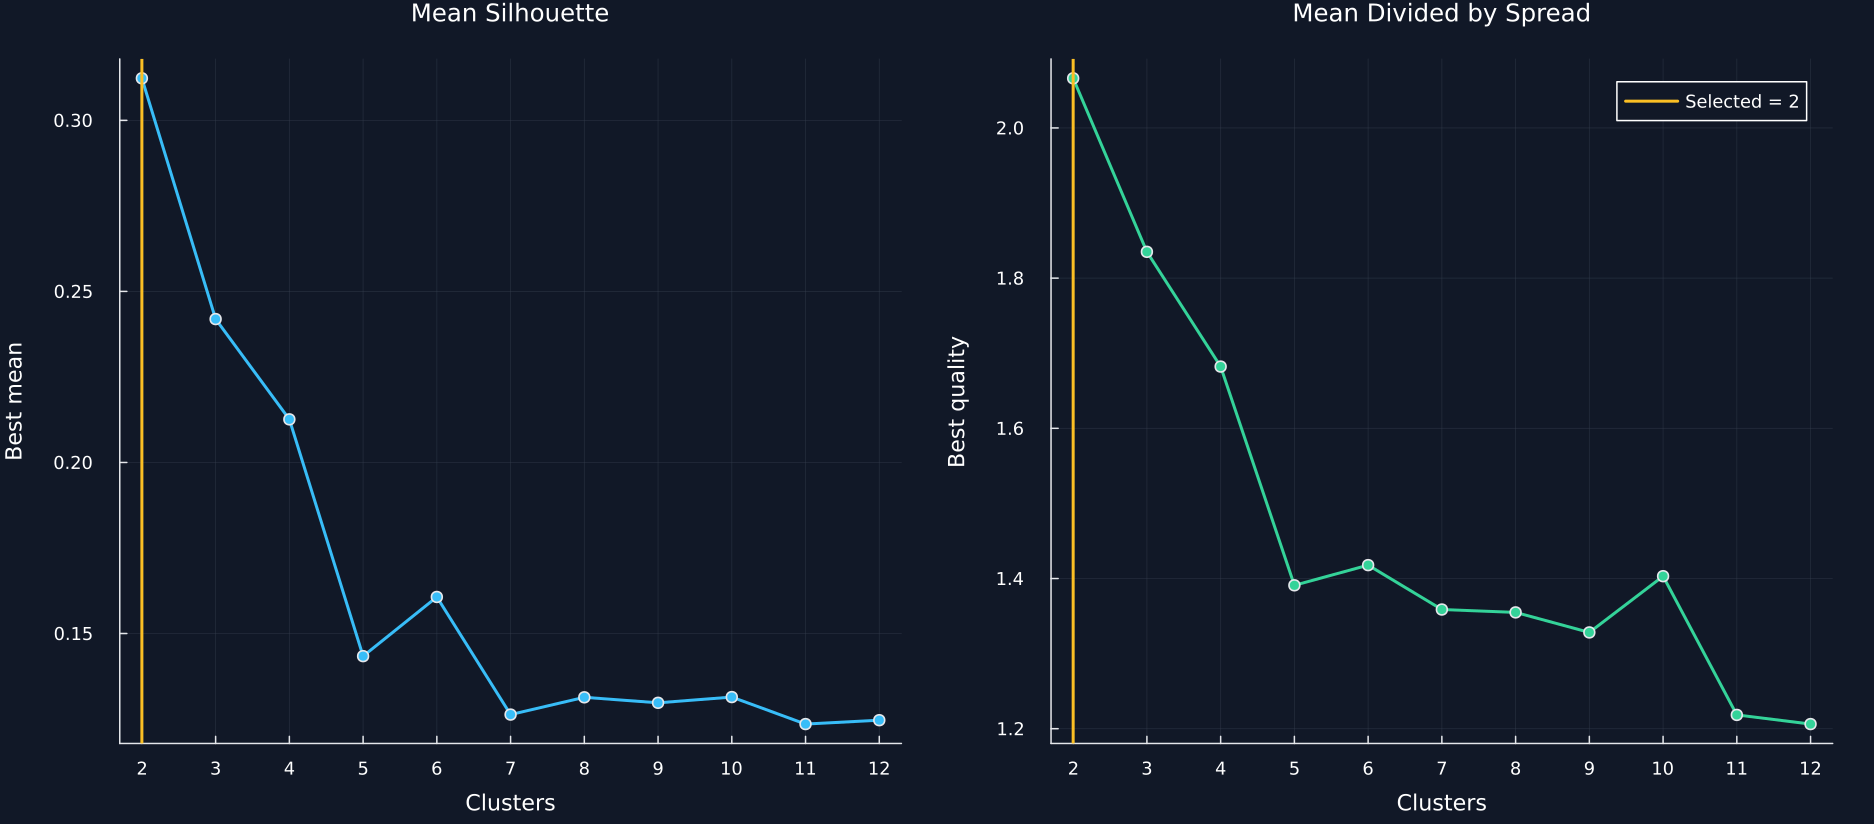

In [3]:
search_rows = NamedTuple[]
best_labels_by_count = Dict{Int,Any}()
provider = candidate_provider(13021,"independent_search")
search_stream = Ref(0)
embedding_distance = RiskLabAI.Cluster._embedding_distances(public_distance)
for repetition in 1:20,cluster_count in 2:12
    labels = provider(public_distance,cluster_count,search_stream)
    scores = silhouette_samples(embedding_distance,labels)
    spread = std(scores;corrected=false)
    quality = mean(scores)/spread
    seed = last(candidate_fits).seed
    push!(search_rows,(Clusters=cluster_count,Repetition=repetition,Mean=mean(scores),Spread=spread,Quality=quality,Seed=seed))
    previous = get(best_labels_by_count,cluster_count,nothing)
    if previous===nothing || quality>previous.quality
        best_labels_by_count[cluster_count] = (;quality,labels,scores,seed)
    end
end
cluster_search_paths = DataFrame(search_rows)
rename!(cluster_search_paths,:Mean=>"Mean silhouette",:Spread=>"Silhouette standard deviation")
cluster_quality = DataFrame([(Clusters=count,Mean=mean(best_labels_by_count[count].scores),Spread=std(best_labels_by_count[count].scores;corrected=false),Quality=best_labels_by_count[count].quality,Seed=best_labels_by_count[count].seed) for count in 2:12])
rename!(cluster_quality,:Mean=>"Best mean silhouette",:Spread=>"Best silhouette standard deviation",:Quality=>"Best quality",:Seed=>"Best seed")
selected_count = cluster_quality.Clusters[argmax(cluster_quality[!,"Best quality"])]
base_sorted,base_clusters,base_silhouette = cluster_fit(public_correlation,13021,"base_search")
base_labels = labels_from_clusters(49,base_clusters)
independently_selected_labels = best_labels_by_count[selected_count].labels
table(cluster_quality,"cluster_quality","Best public silhouette quality for each candidate cluster count.")
save_data(cluster_search_paths,paths,"cluster_search_paths")
save_candidates("base")
first_panel = plot(cluster_quality.Clusters,cluster_quality[!,"Best mean silhouette"];color=palette.cyan,marker=:circle,title="Mean Silhouette",xlabel="Clusters",ylabel="Best mean",xticks=2:12,label=false)
vline!(first_panel,[selected_count];color=palette.amber,label=false)
second_panel = plot(cluster_quality.Clusters,cluster_quality[!,"Best quality"];color=palette.green,marker=:circle,title="Mean Divided by Spread",xlabel="Clusters",ylabel="Best quality",xticks=2:12,label=false)
vline!(second_panel,[selected_count];color=palette.amber,label="Selected = $selected_count")
save_figure(plot(first_panel,second_panel;layout=(1,2),size=(1250,550)),paths,"public_cluster_quality");


## Base Clustering Result

Row,Cluster,Size,Mean silhouette,Minimum silhouette,Mean within correlation,Industries
,Int64,Int64,Float64,Float64,Float64,String
1,1,44,0.330776,0.0462158,0.619203,"Agric, Food, Soda, Beer, Toys, Fun, Books, Hshld, Clths, Hlth, MedEq, Drugs, Chems, Rubbr, Txtls, BldMt, Cnstr, Steel, FabPr, Mach, ElcEq, Aero, Ships, Mines, Oil, Util, Telcm, PerSv, BusSv, Hardw, Softw, Chips, LabEq, Paper, Boxes, Trans, Whlsl, Rtail, Meals, Banks, Insur, RlEst, Fin, Other"
2,2,5,0.149627,-0.0208208,0.236933,"Smoke, Autos, Guns, Gold, Coal"


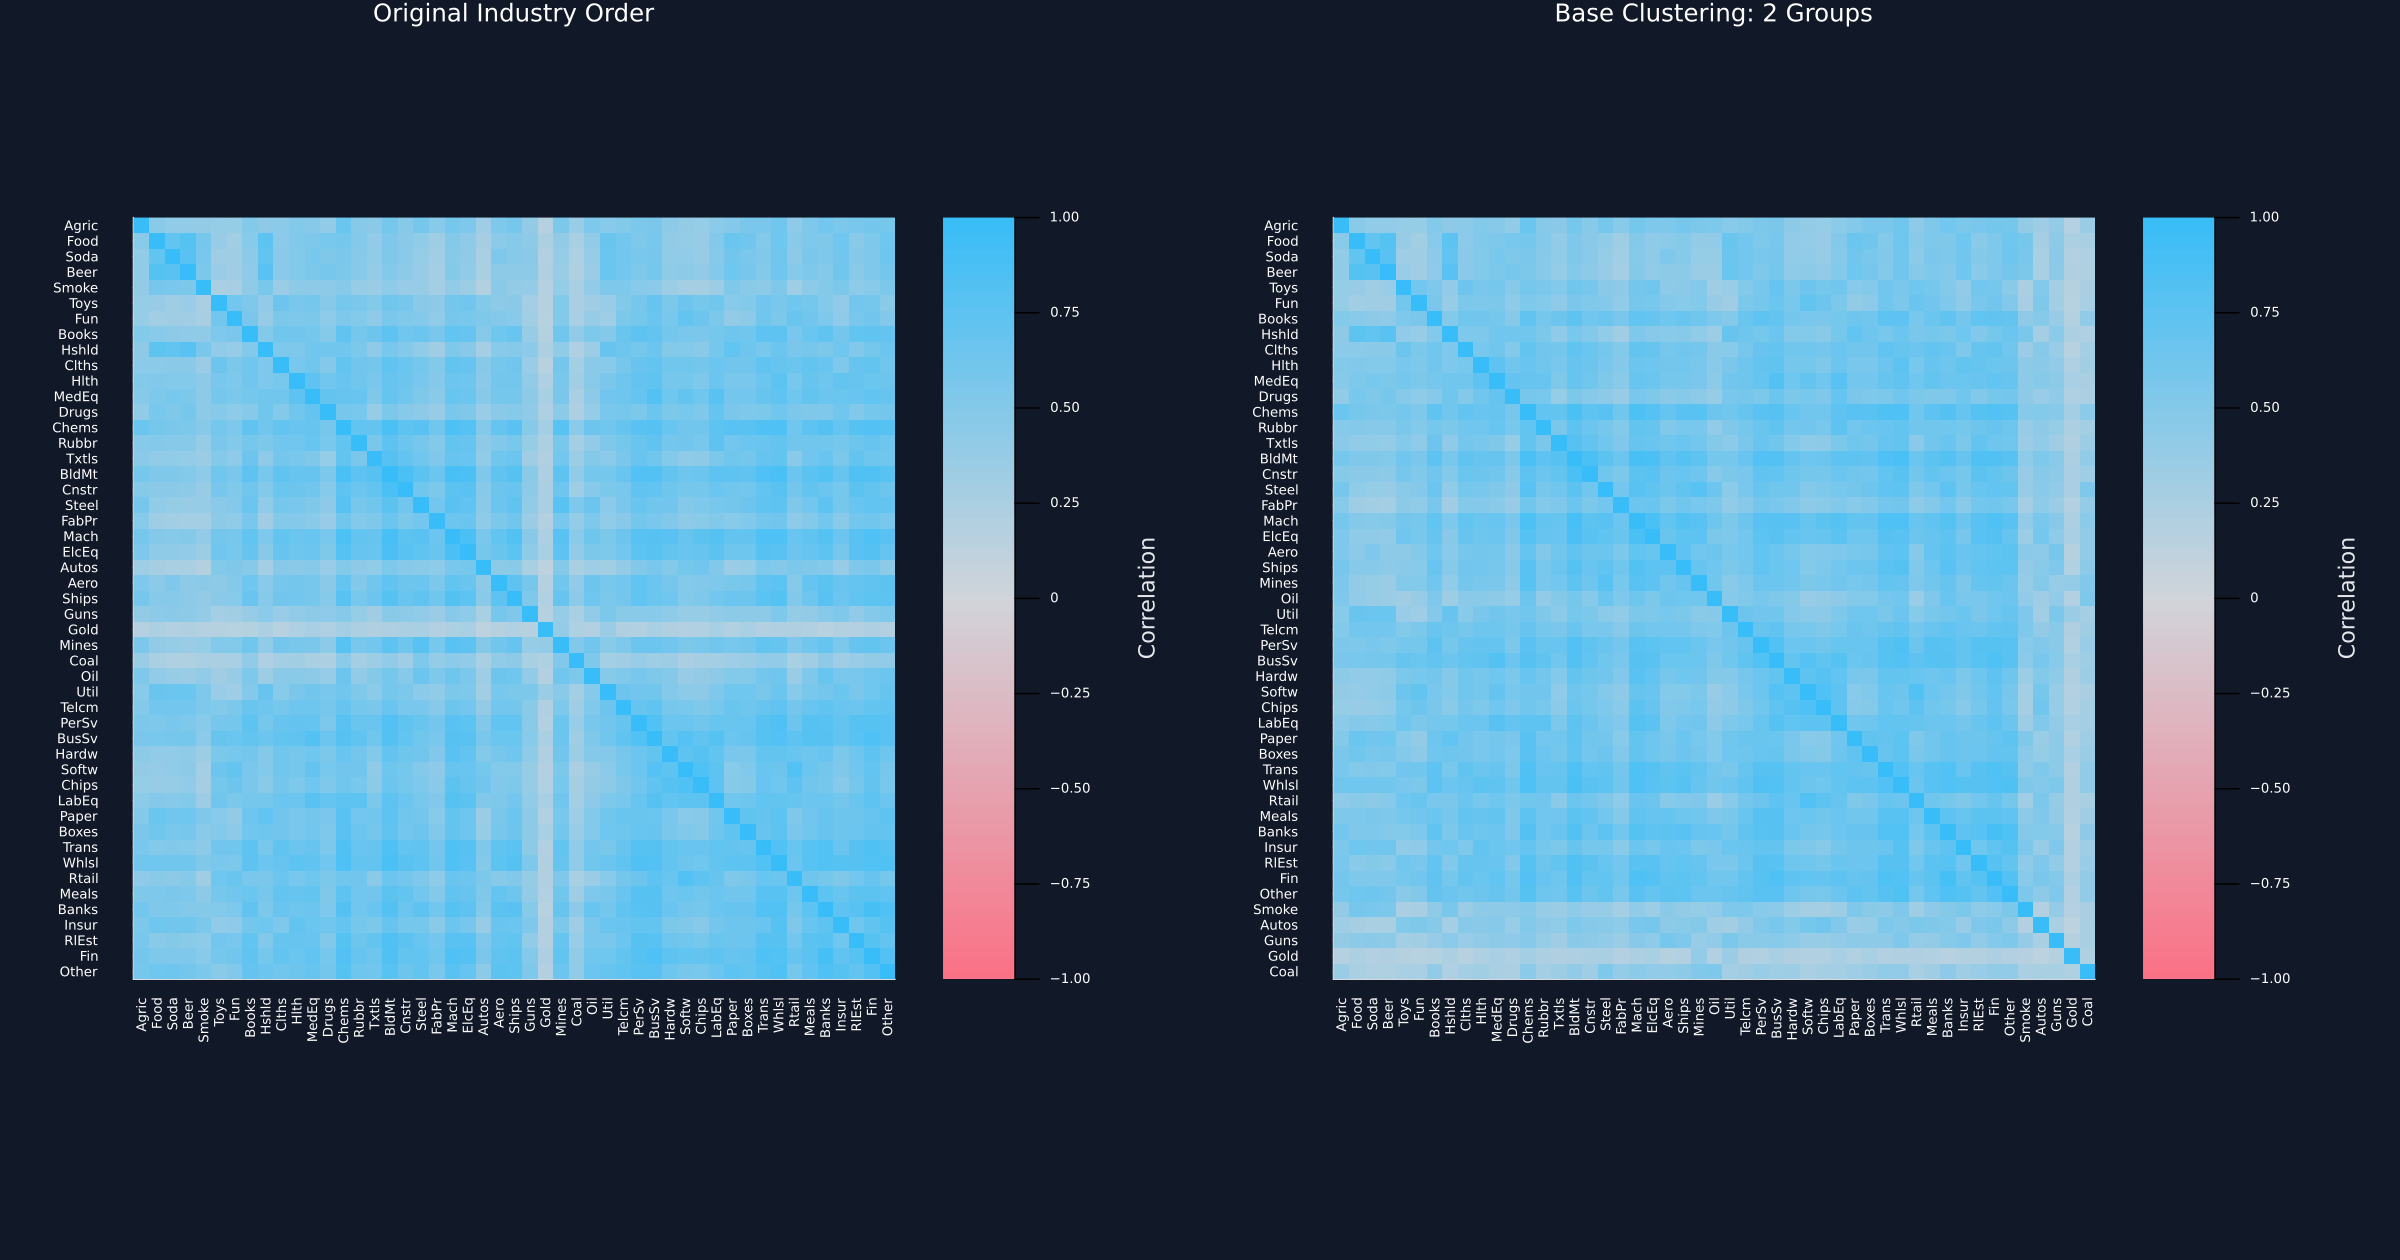

In [4]:
base_cluster_summary = cluster_summary(public_correlation,base_clusters,base_silhouette)
table(base_cluster_summary,"base_cluster_summary","Base public clusters chosen by the released search.")
order = sortperm(base_labels)
figure = plot(correlation_panel(public_correlation,"Original Industry Order";labels=industry_names),correlation_panel(base_sorted,"Base Clustering: $(length(base_clusters)) Groups";labels=industry_names[order]);layout=(1,2),size=(1600,840),bottom_margin=12Plots.mm,left_margin=8Plots.mm)
save_figure(figure,paths,"public_base_clusters");


## Tests

In [5]:
@assert size(industry_returns)==(1760,49)
@assert size(public_correlation)==(49,49)
@assert size(public_distance)==(49,49)
@assert diag(public_correlation)≈ones(49)
@assert diag(public_distance)≈zeros(49)
@assert public_correlation≈transpose(public_correlation)
@assert public_distance≈transpose(public_distance)
@assert minimum(public_distance)>=0
@assert maximum(public_distance)<=1
@assert size(correlation_summary)==(7,2)
@assert size(cluster_search_paths)==(220,6)
@assert size(cluster_quality)==(11,5)
@assert cluster_quality.Clusters==collect(2:12)
@assert 2<=selected_count<=12
@assert length(base_clusters)==selected_count
@assert Set(reduce(vcat,values(base_clusters)))==Set(1:49)
@assert sum(length,values(base_clusters))==49
@assert size(base_sorted)==(49,49)
@assert length(base_silhouette)==49
@assert all(-1 .<=base_silhouette.<=1)
@assert base_labels==independently_selected_labels
@assert mean(base_silhouette)/std(base_silhouette;corrected=false)≈maximum(cluster_quality[!,"Best quality"])
@assert size(base_cluster_summary)==(selected_count,6)
@assert sum(base_cluster_summary.Size)==49
@assert all(-1 .<=base_cluster_summary[!,"Mean within correlation"].<=1)
@assert length(candidate_fits)==440
@assert length(candidate_labels)==440*49
@assert isfile(joinpath(paths.figures,"public_cluster_quality.pdf"))
@assert isfile(joinpath(paths.figures,"public_base_clusters.pdf"))
@assert isfile(joinpath(paths.tables,"correlation_summary.tex"))
@assert isfile(joinpath(paths.tables,"cluster_quality.tex"))
@assert isfile(joinpath(paths.tables,"base_cluster_summary.tex"))
println("Native correlation embeddings, 440 candidate fits and independent selection assertions passed.");


Native correlation embeddings, 440 candidate fits and independent selection assertions passed.